# Benchmarking

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 07.07.2025
- Date of Last Modification: 08.08.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

# 1. Setup

## 1.1 Load Libraries 

In [117]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [118]:
import sys
sys.path.append("../../utils")

In [119]:
import os
import pickle
import re
import warnings

import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from datasets import load_from_disk
from sklearn.model_selection import train_test_split

from app.infer import (embed_dataset,
                       get_average_gene_embed,
                       harmonize_adata,
                       perturb_dataset,
                       tokenize_adata)
from nichejepa.evaluation import (compute_neighborhood_composition,
                                  get_adata_cellphonedb_lr_pairs,
                                  get_adata_omnipath_lr_pairs,
                                  knn_classifier,
                                  linear_classifier,
                                  linear_regressor,
                                  plot_roc_curve)
from nichejepa.preprocessors.filters import filter_cells
from nichejepa.preprocessors.graph import construct_neighbor_graph

from analysis_utils import *

## 1.2 Define Params

In [5]:
model_timestamp = '11062025_183320_055'

# Inference params
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None
force_recompute_output_embed = False

# Tokenizer params
num_shards = 32
nproc = 4
n_neighs = 10
force_retokenize = False

## 1.3 Configure Paths

In [45]:
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'
model_folder_path = f'{artifacts_folder_path}/models/{model_timestamp}'

In [47]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)

## 1.4 Run Notebook Setup

In [41]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [42]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [43]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [46]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

# 2. Experiments

## 2.1 xhs1000-39b_1p (Xenium Human Skin Eczema)

In [50]:
# Dataset variables
dataset_name = 'xhs1000-39b_1p'
cell_type_key = 'annotation_new7'
niche_key = 'NICHE_NAMES'
sample_key = 'batch'
file_paths = [
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/adata_batch11.h5ad', # held out from pretraining
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/adata_batch19.h5ad', # held out from pretraining
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/adata_batch32.h5ad', # held out from pretraining
]
spot_size = 20

### 2.1.1 Visualize Ground Truth Niches

In [97]:
for file_path in file_paths:
    # Load AnnData
    adata = sc.read_h5ad(file_path)

    # Harmonize AnnData
    adata = harmonize_adata(adata)
    adata_list.append(adata)

STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle


Number of genes with matching ensembl IDs:           4948.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...
STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle


Number of genes with matching ensembl IDs:           4948.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...


/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle


Number of genes with matching ensembl IDs:           4948.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...


In [98]:
set(adata_list[0].obs[niche_key].unique().tolist() +
    adata_list[1].obs[niche_key].unique().tolist() +
    adata_list[2].obs[niche_key].unique().tolist())

{'Basal epidermis/superficial dermis',
 'Epidermis with T2',
 'Interstitial stroma',
 'KC',
 'KC_T2_LC',
 'Muscle',
 'Perivascular depeer',
 'Perivascular superficial',
 'Schwann_KC_HF',
 'Sebocyte',
 'Sweat gland1',
 'Sweat gland2'}

In [99]:
# Define niche palette
label2niche = {
    '0': 'Basal epidermis/superficial dermis',
    '1': 'Perivascular superficial',
    '2': 'KC_T2_LC',
    '3': 'KC',
    '4': 'Perivascular depeer',
    '5': 'Interstitial stroma',
    '6': 'Sebocyte',
    '7': 'Schwann_KC_HF',
    '8': 'Muscle',
    '9': 'Sweat gland2',
    '10': 'Sweat gland1',
    '11': 'Epidermis with T2'
}

niche_palette = {
    label2niche.get(k, k): v
    for k, v in custom_palette.items()
}

{'BK18_Lesional Baseline'}


/tmp/ipykernel_2092058/3353837455.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


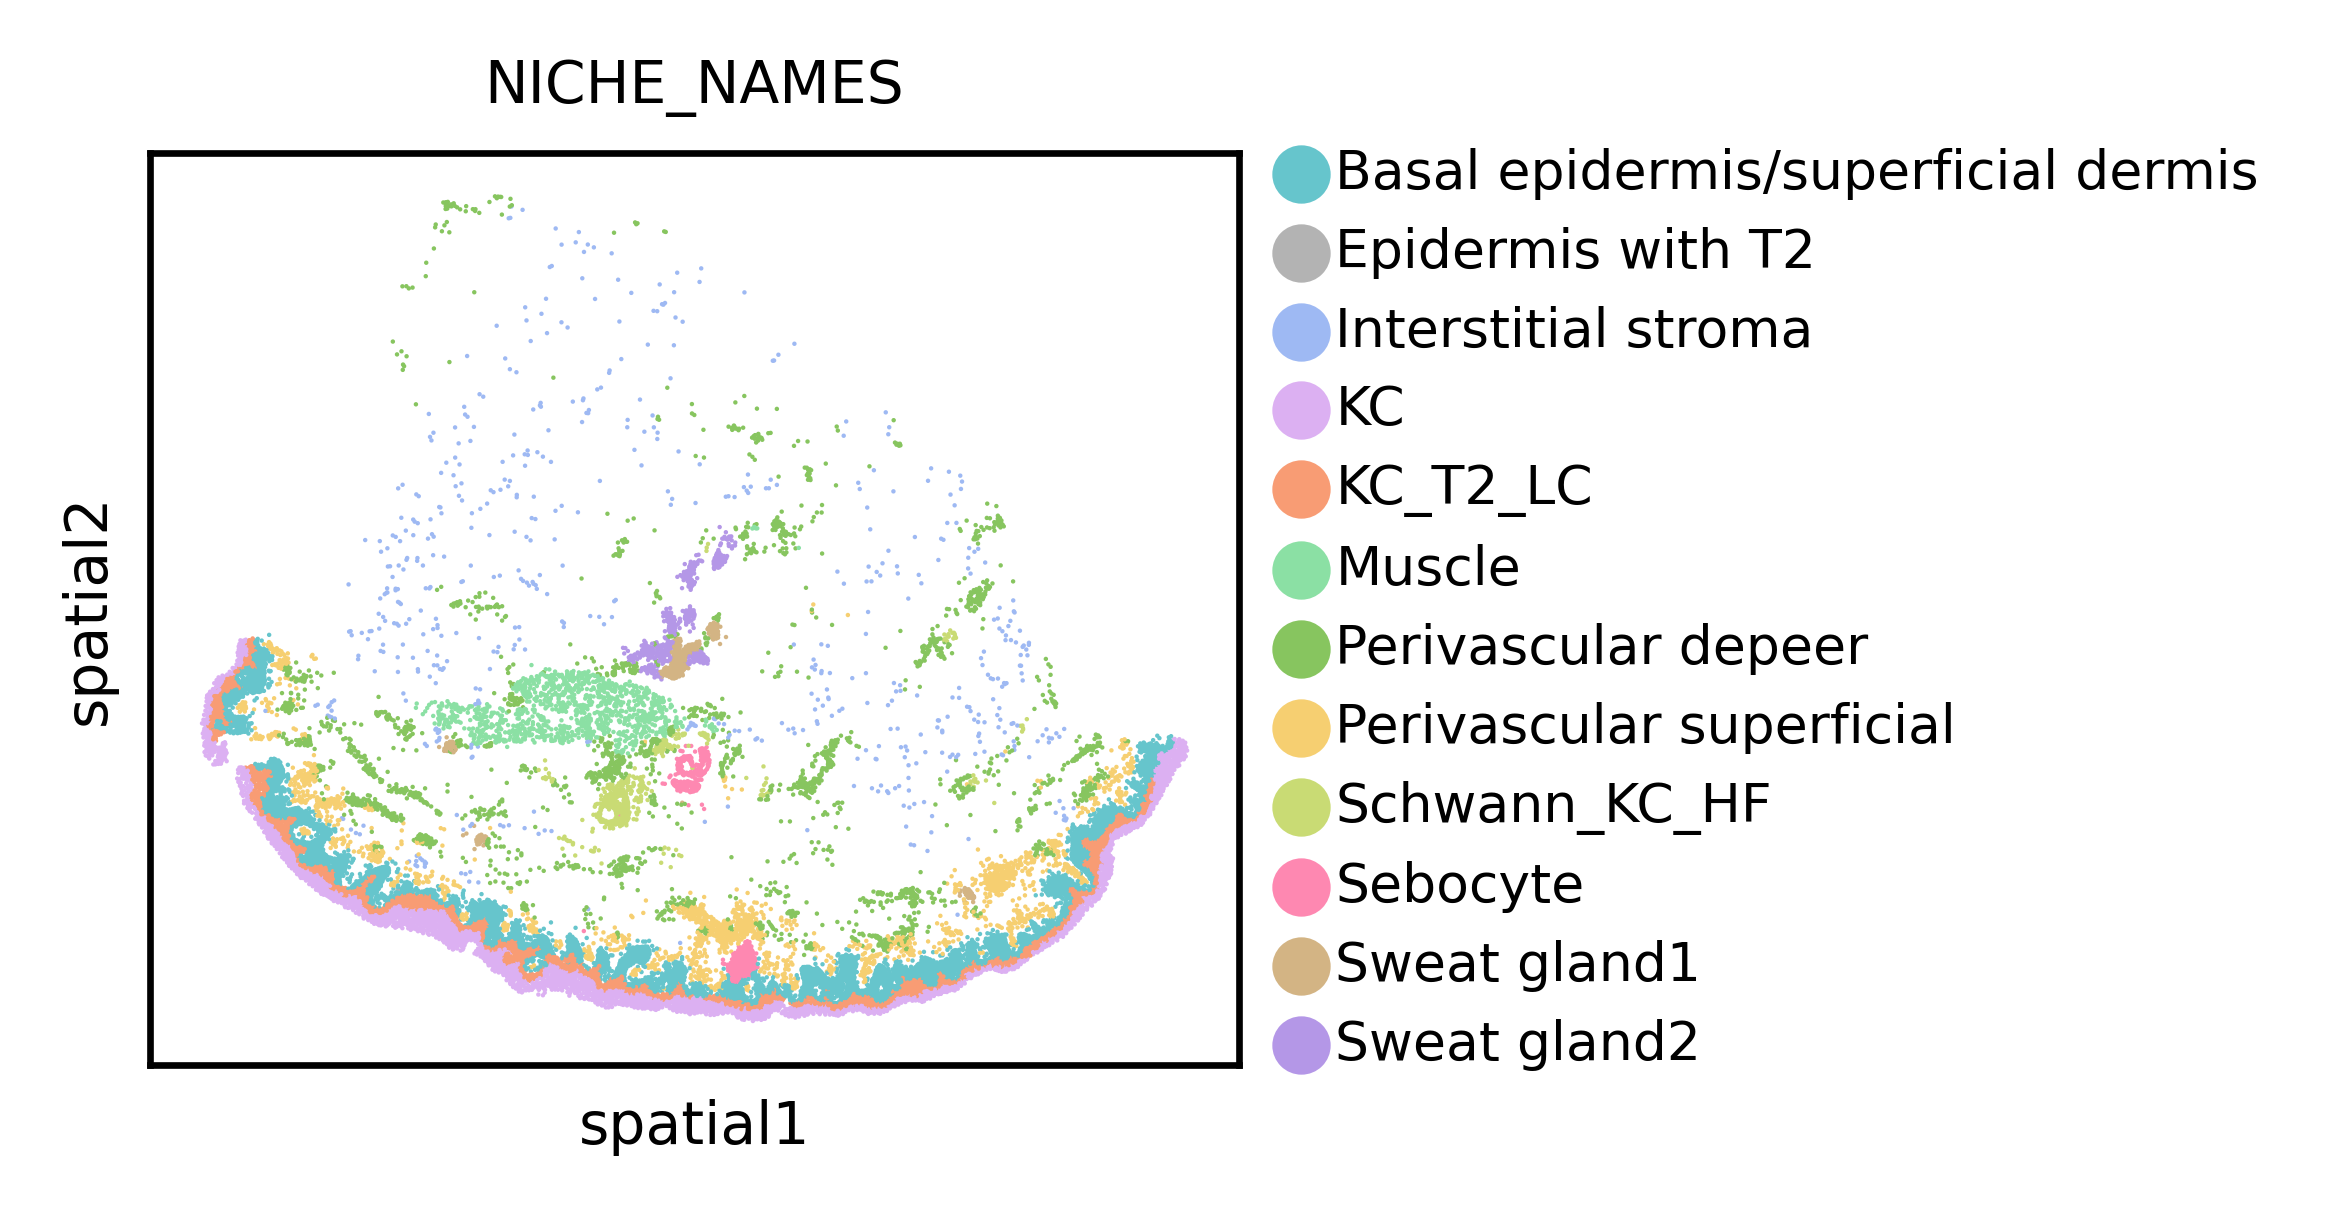

{'BK30_Lesional Baseline'}


/tmp/ipykernel_2092058/3353837455.py:13: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


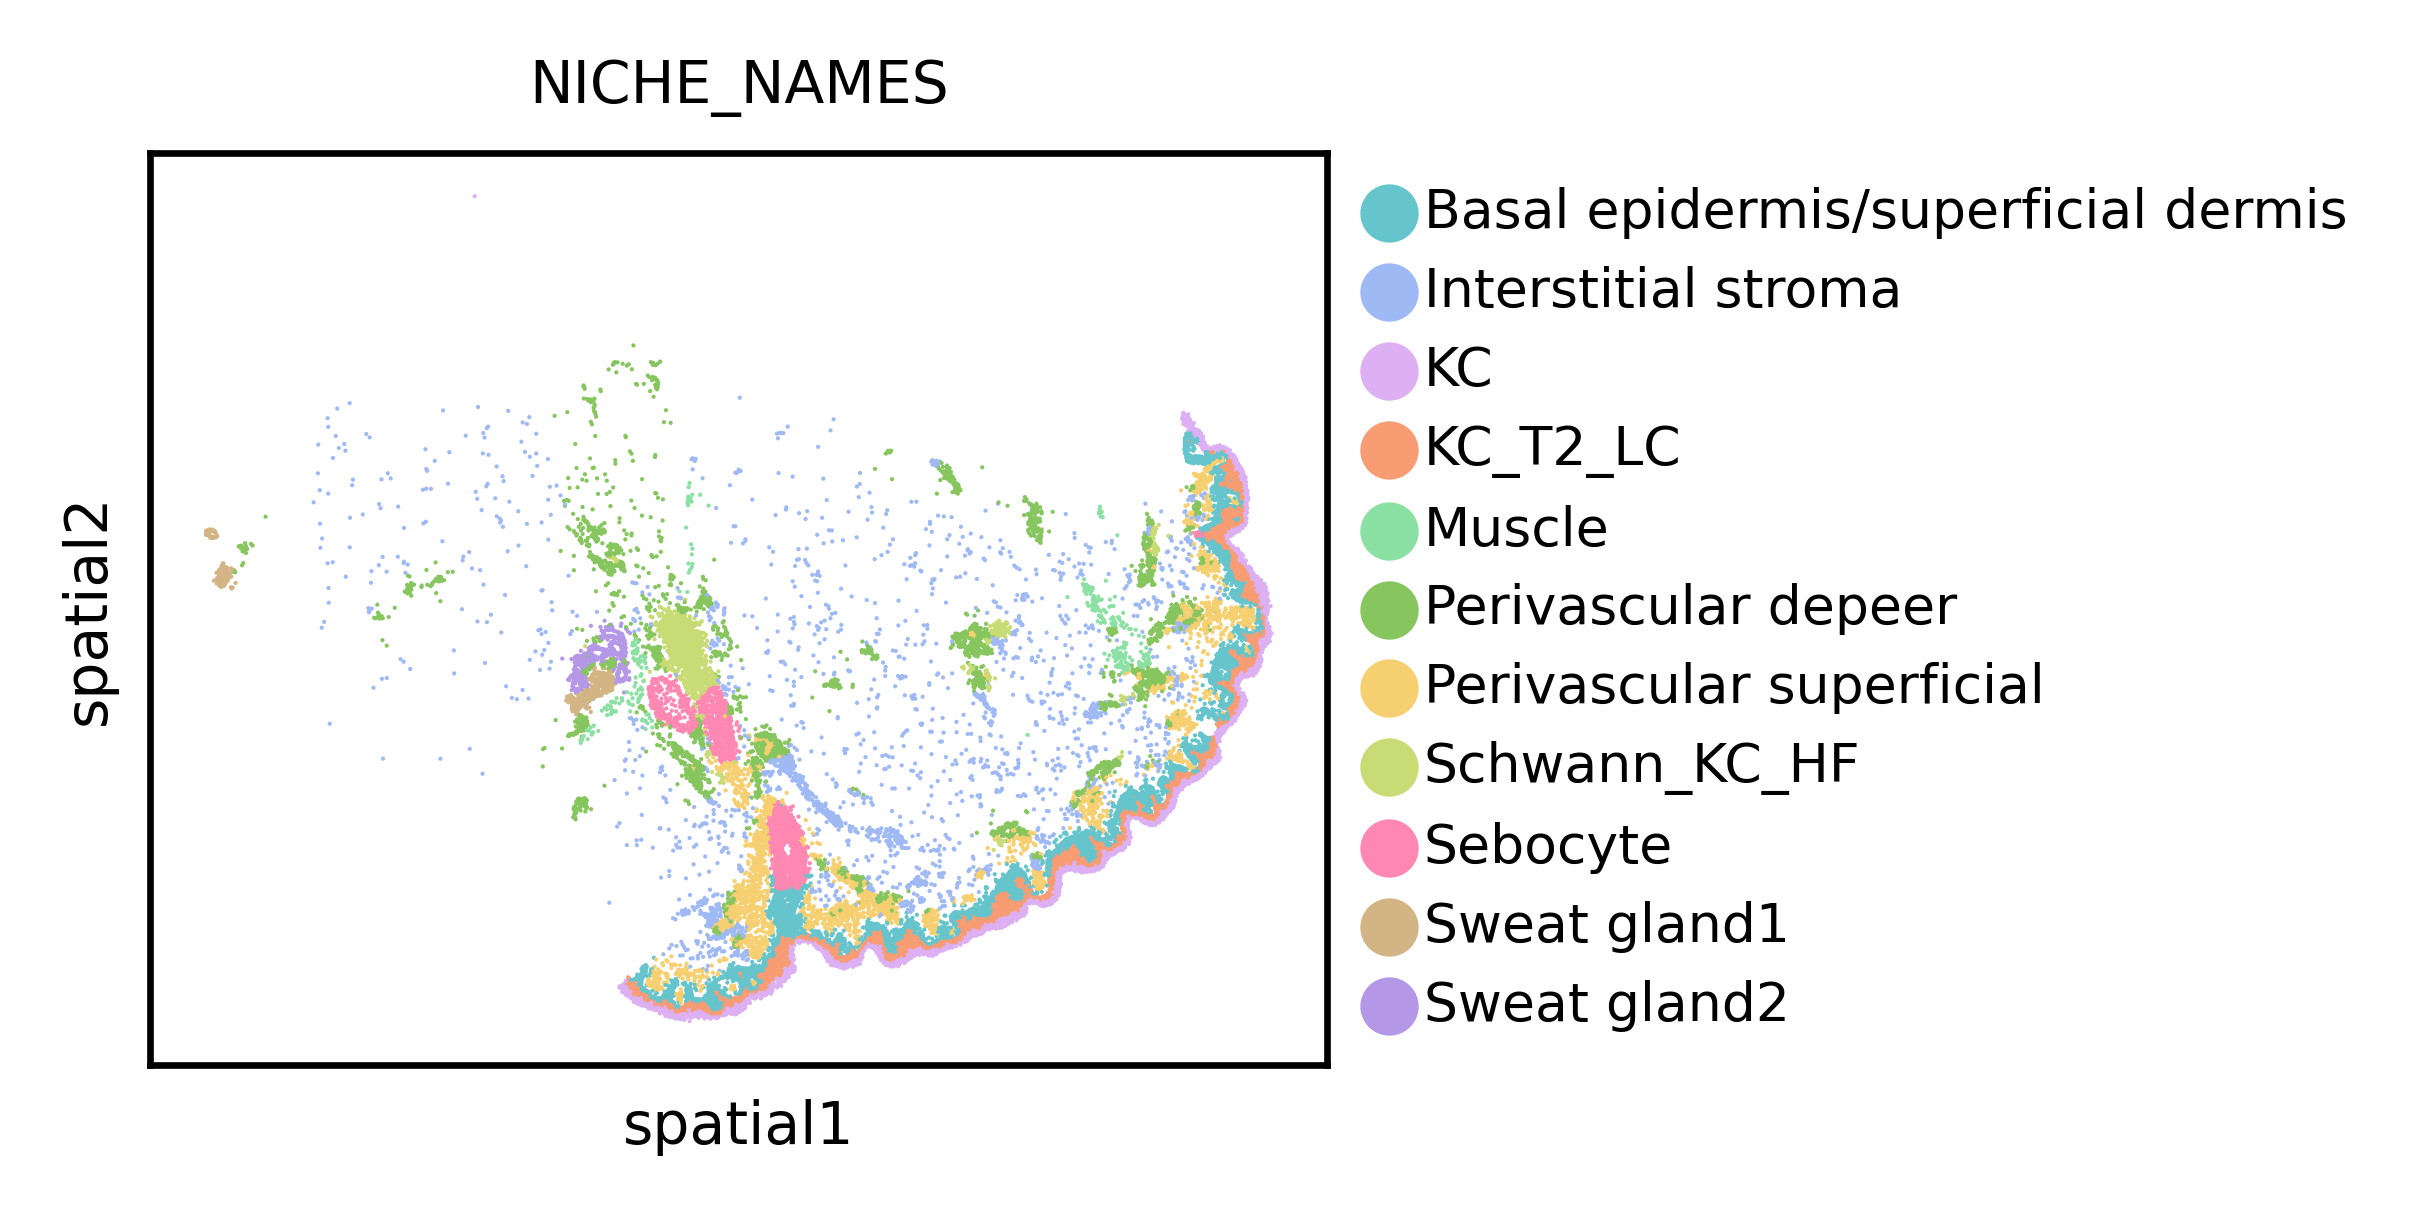

In [100]:
# Visualize ground truth niche labels in training samples
print(set(adata_list[0].obs['sample'].tolist()))
file_name = f'{dataset_name}_batch11_niche_label_transfer_ground_truth_niches.svg'
sc.pl.spatial(
    adata_list[0],
    color=niche_key,
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)

print(set(adata_list[2].obs['sample'].tolist()))
file_name = f'{dataset_name}_batch32_niche_label_transfer_ground_truth_niches.svg'
sc.pl.spatial(
    adata_list[2],
    color=niche_key,
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

{'BK39_Lesional Baseline'}


/tmp/ipykernel_2092058/2745407567.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


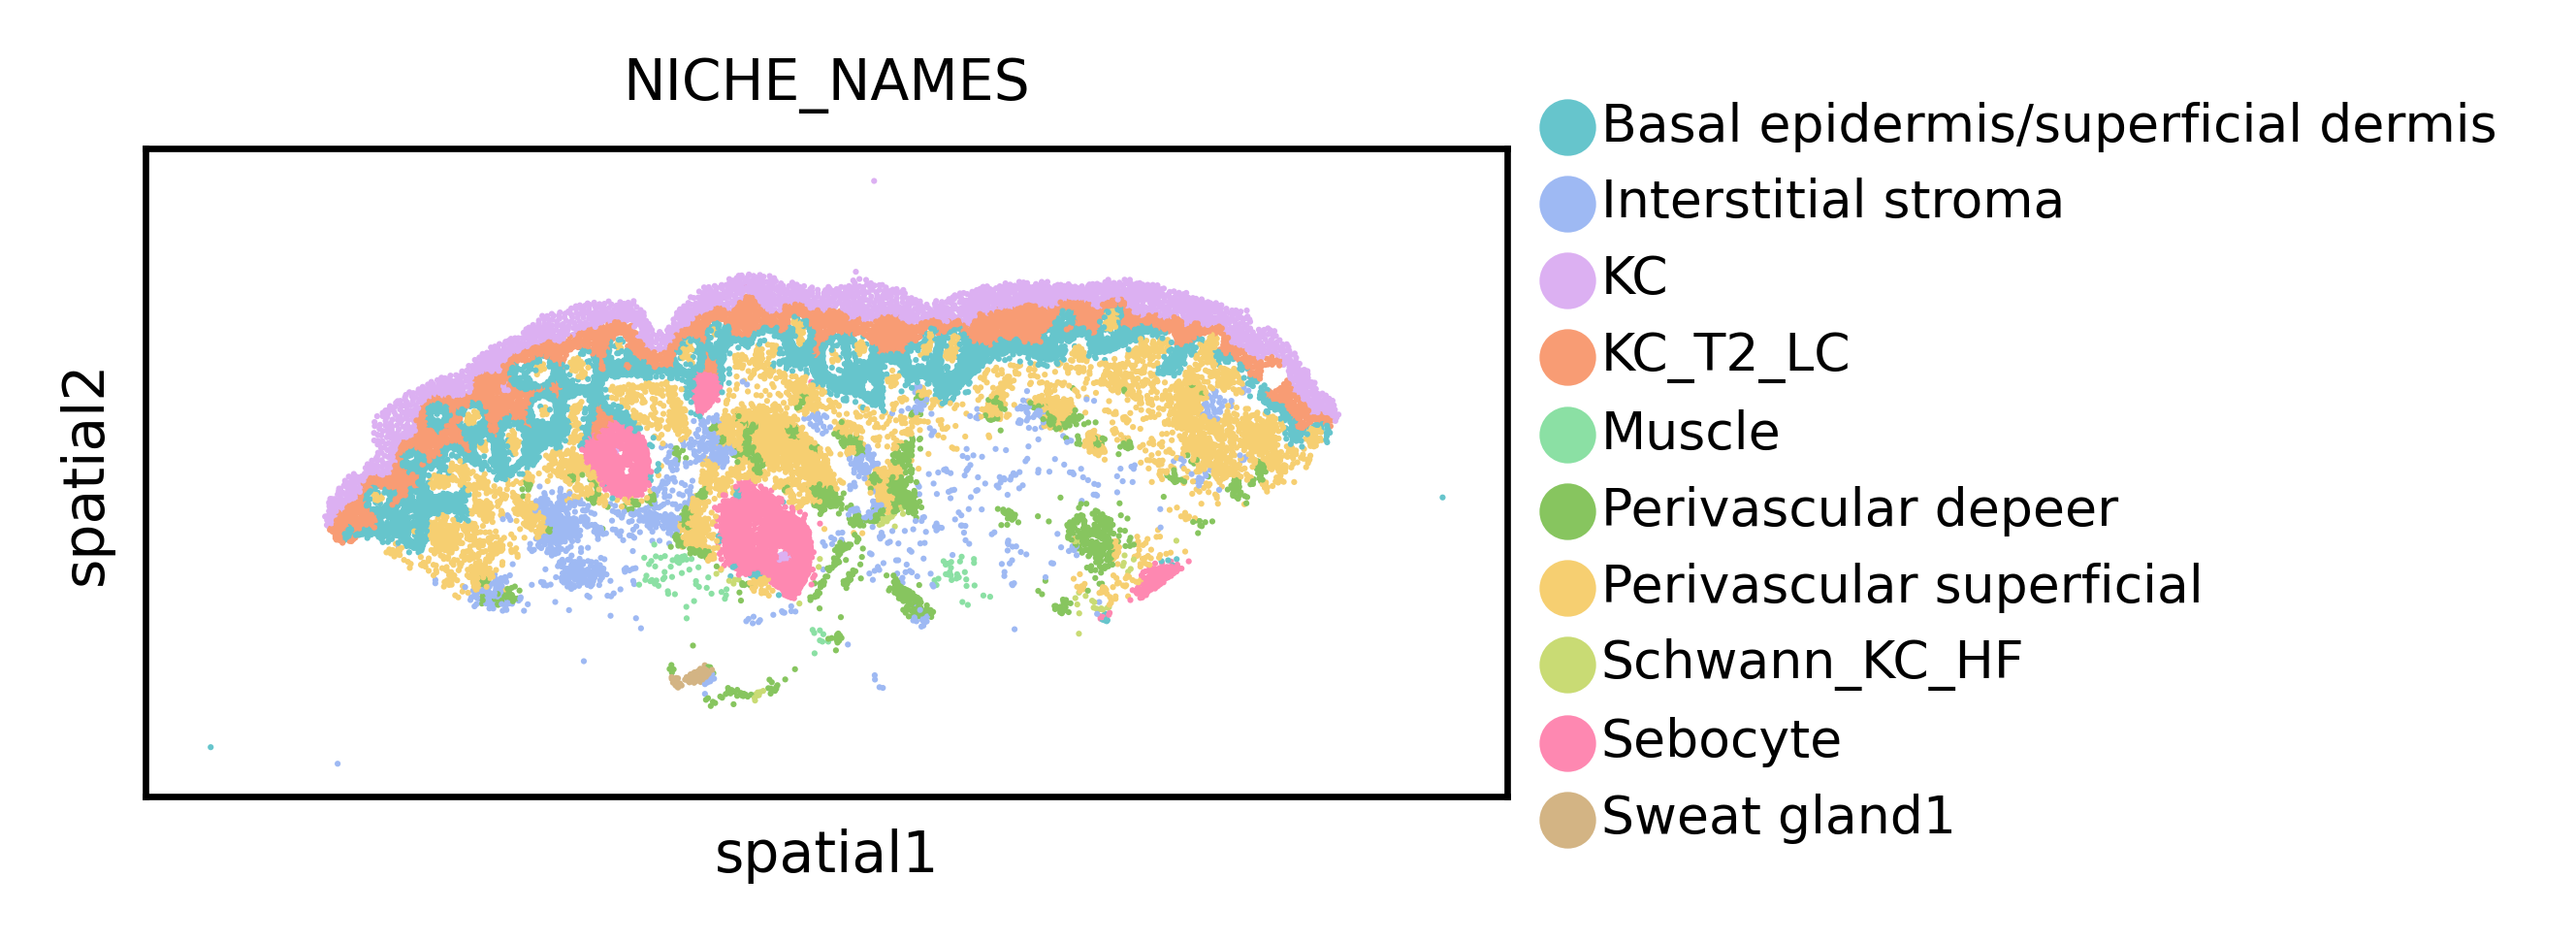

In [101]:
# Visualize ground truth niche labels in test sample
print(set(adata_list[1].obs['sample'].tolist()))
file_name = f'{dataset_name}_batch19_niche_label_transfer_ground_truth_niches.svg'
sc.pl.spatial(
    adata_list[1],
    color=niche_key,
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

### 2.1.2 NicheJEPA

#### 2.1.2.1 Retrieve Embeddings

In [ ]:
# Harmonize and tokenize data and retrieve embeddings
adata_list = []
dataset_list = []
output_embed_list = []

for file_path in file_paths:
    # Load AnnData
    adata = sc.read_h5ad(file_path)

    # Harmonize AnnData
    adata = harmonize_adata(adata)
    adata_list.append(adata)

    # Load tokenized AnnData or tokenize data
    dataset_path = f'{artifacts_folder_path}/{dataset_name}/{file_path.split("/")[-1].split(".")[0]}.dataset'
    if os.path.exists(dataset_path) and not force_retokenize:
        dataset = load_from_disk(dataset_path)
        print('Filtering cells...')
        # Filter cells based on adata.obs['filter_pass']
        adata = filter_cells(adata)   
        
        print('Computing spatial neighborhood...')
        # Construct neighbor graph
        adata = construct_neighbor_graph(
            adata,
            n_neighs=n_neighs,
            radius=None,
            delaunay=None,
            include_self_loop=False,
            compute_neighbor_counts=False)
    else:
        # Tokenize AnnData
        dataset = tokenize_adata(
            adata,
            model_folder_path,
            nproc=nproc,
            processing_mode='parallel')

        # Save tokenized data
        os.makedirs(f'{artifacts_folder_path}/{dataset_name}', exist_ok=True)
        dataset.save_to_disk(
            dataset_path,
            num_shards=num_shards)
    dataset_list.append(dataset)

    # Retrieve cell and neighborhood embeddings
    output_embed_path = f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}/{file_path.split("/")[-1].split(".")[0]}_output_embed.pkl'
    if os.path.exists(output_embed_path) and not force_recompute_output_embed:
        with open(output_embed_path, 'rb') as f:
            output_embed = pickle.load(f)
    else:
        # Compute embeddings
        output_embed = embed_dataset(
            dataset=dataset,
            model_folder_path=model_folder_path,
            emb_layer=emb_layer,
            agg_excluded_tokens=agg_excluded_tokens,
            top_k=top_k,
            batch_size=batch_size,
            pin_memory=pin_memory,
            num_workers=num_workers)

        # Save embeddings
        os.makedirs(f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}', exist_ok=True)
        with open(output_embed_path, 'wb') as f:
            pickle.dump(output_embed, f)
    output_embed_list.append(output_embed)

for i in range(len(adata_list)):
    adata_list[i].obs['batch'] = adata_list[i].uns['batch']

# Concatenate AnnData objects of all samples/batches
adata = sc.concat(adata_list, axis=0)

# Retrieve cell and neighborhood embeddings for all samples/batches
cell_emb = np.concatenate([output_embed['cell_emb'] for output_embed in output_embed_list], axis=0)
spatial_cell_emb = np.concatenate([output_embed['spatial_cell_emb'] for output_embed in output_embed_list], axis=0)
neighborhood_emb = np.concatenate([output_embed['neighborhood_emb'] for output_embed in output_embed_list], axis=0)

# Add embeddings to AnnData object
adata.obsm['cell_emb'] = cell_emb
adata.obsm['spatial_cell_emb'] = spatial_cell_emb
adata.obsm['neighborhood_emb'] = neighborhood_emb

# Add combined neighborhood graph
blocks = [a.obsp['spatial_connectivities'] for a in adata_list]
combined_graph = sp.block_diag(blocks)
adata.obsp['spatial_connectivities'] = combined_graph.tocsr()

# Write to disk
adata.write(f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}/{file_path.split("/")[-1].split(".")[0]}.h5ad')

### 2.1.3 CellPLM

#### 2.1.3.1 Retrieve Embeddings

In [ ]:
# Load AnnData with embeddings
adata = sc.read_h5ad('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/benchmarking/CellPLM/xhs1000-39b_1p_embedded.h5ad')

### 2.1.4 Nicheformer

### 2.1.5 Novae

### 2.1.6 scGPT-spatial

In [121]:
method = 'scGPT-spatial'
niche_key = 'niche_type'
emb_key = 'X'

#### 2.1.6.1 Retrieve Embeddings

In [122]:
adata_emb = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/{method}/xhs1000-39b_1p_embedded.h5ad')

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [123]:
# Filter cells with missing labels
adata_filtered = adata_emb[~adata_emb.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
print(cat_counts)
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

niche_type
Basal epidermis/superficial dermis    12668
Perivascular superficial               8740
KC_T2_LC                               7113
KC                                     6345
Perivascular depeer                    6265
Interstitial stroma                    3998
Sebocyte                               3656
Schwann_KC_HF                          1701
Muscle                                 1468
Sweat gland2                            858
Sweat gland1                            842
Epidermis with T2                         1
Name: count, dtype: int64


#### 2.1.6.2 Train Niche Transfer Classifiers

##### 2.1.6.2.1 Linear Classifier

In [124]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm[emb_key]

In [ ]:
start_seed = 0
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = niche_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    niche_labels_train = niche_labels[train_indices]
    niche_labels_val = niche_labels[val_indices]
    niche_labels_test = niche_labels[test_indices]

    # Train and evaluate linear niche transfer classifier
    pred_niche_labels_test, _, _, model = linear_classifier(
        features_train=niche_features_train,
        labels_train=niche_labels_train,
        features_val=niche_features_val,
        labels_val=niche_labels_val,
        features_test=niche_features_test,
        labels_test=niche_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_linear_classifier_cls_report_seed_{seed}.txt'
        )
    
    #print(niche_categories[pred_niche_labels_test])

Using device: cuda
Epoch 1: Train Loss = 602.3676, Val Loss = 2.3055
Epoch 2: Train Loss = 580.6888, Val Loss = 2.2352
Epoch 3: Train Loss = 565.7574, Val Loss = 2.1861
Epoch 4: Train Loss = 554.8243, Val Loss = 2.1500
Epoch 5: Train Loss = 546.7574, Val Loss = 2.1219
Epoch 6: Train Loss = 540.2863, Val Loss = 2.0985
Epoch 7: Train Loss = 534.9146, Val Loss = 2.0784
Epoch 8: Train Loss = 530.0198, Val Loss = 2.0603
Epoch 9: Train Loss = 525.1970, Val Loss = 2.0438
Epoch 10: Train Loss = 520.9098, Val Loss = 2.0284
Epoch 11: Train Loss = 517.4719, Val Loss = 2.0140
Epoch 12: Train Loss = 514.1350, Val Loss = 2.0004
Epoch 13: Train Loss = 510.5884, Val Loss = 1.9874
Epoch 14: Train Loss = 507.0259, Val Loss = 1.9749
Epoch 15: Train Loss = 504.1079, Val Loss = 1.9629
Epoch 16: Train Loss = 501.9929, Val Loss = 1.9514
Epoch 17: Train Loss = 499.1235, Val Loss = 1.9402
Epoch 18: Train Loss = 496.2185, Val Loss = 1.9294
Epoch 19: Train Loss = 492.9834, Val Loss = 1.9188
Epoch 20: Train Loss 

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metr

Epoch 1: Train Loss = 600.9667, Val Loss = 2.3005
Epoch 2: Train Loss = 579.9007, Val Loss = 2.2320
Epoch 3: Train Loss = 565.4666, Val Loss = 2.1836
Epoch 4: Train Loss = 555.3796, Val Loss = 2.1480
Epoch 5: Train Loss = 547.2328, Val Loss = 2.1201
Epoch 6: Train Loss = 540.6051, Val Loss = 2.0967
Epoch 7: Train Loss = 534.8926, Val Loss = 2.0764
Epoch 8: Train Loss = 530.5548, Val Loss = 2.0581
Epoch 9: Train Loss = 525.9376, Val Loss = 2.0415
Epoch 10: Train Loss = 521.7860, Val Loss = 2.0260
Epoch 11: Train Loss = 518.3590, Val Loss = 2.0113
Epoch 12: Train Loss = 515.2913, Val Loss = 1.9974
Epoch 13: Train Loss = 511.0052, Val Loss = 1.9843
Epoch 14: Train Loss = 507.7944, Val Loss = 1.9716
Epoch 15: Train Loss = 504.9696, Val Loss = 1.9593
Epoch 16: Train Loss = 501.8713, Val Loss = 1.9476
Epoch 17: Train Loss = 498.1515, Val Loss = 1.9362
Epoch 18: Train Loss = 496.0432, Val Loss = 1.9251
Epoch 19: Train Loss = 493.4926, Val Loss = 1.9144
Epoch 20: Train Loss = 490.9562, Val Los

In [ ]:
# Store predictions from last run
adata_test = adata_list[1]
adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]

In [ ]:
# Visualize predicted niche labels in test sample
file_name = f'{method}_{dataset_name}_batch19_niche_label_transfer_linear_classifer_predicted_niches_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_linear',
    palette=niche_palette,
    spot_size=spot_size,
    save=file_name)   

##### 2.1.6.2.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [ ]:
# Train and evaluate linear niche transfer classifier
# 0.828 accuracy
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    results_save_path=f'{benchmarking_artifacts_folder_path}/results/{method}_{dataset_name}_niche_label_transfer_knn_cls_report.txt')

In [ ]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
file_name = f'{method}_{dataset_name}_batch19_niche_label_transfer_linear_classifer_predicted_niches_seed_{seed}.svg'
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=custom_palette,
    spot_size=spot_size,
    save=file_name)   

In [61]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm['neighborhood_emb']

In [ ]:
start_seed = 0
n_seeds = 8

for seed in range(n_seeds):
    # Get train and validation indices
    train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    train_val_labels = niche_labels[train_val_indices]
    train_indices, val_indices = train_test_split(
        train_val_indices,
        test_size=0.1,
        random_state=seed,
        stratify=train_val_labels
    )
    
    # Get test indices
    test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
    
    # Split features and labels
    niche_features_train = niche_features[train_indices]
    niche_features_val = niche_features[val_indices]
    niche_features_test = niche_features[test_indices]
    niche_labels_train = niche_labels[train_indices]
    niche_labels_val = niche_labels[val_indices]
    niche_labels_test = niche_labels[test_indices]

    # Train and evaluate linear niche transfer classifier
    pred_niche_labels_test, _, _, model = linear_classifier(
        features_train=niche_features_train,
        labels_train=niche_labels_train,
        features_val=niche_features_val,
        labels_val=niche_labels_val,
        features_test=niche_features_test,
        labels_test=niche_labels_test,
        n_epochs=500,
        batch_size=128,
        results_save_path=f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_niche_label_transfer_cls_report_seed_{seed}.txt'
        )
    
    #print(niche_categories[pred_niche_labels_test])

In [86]:
# Retrieve F1 scores
weighted_avg_f1_scores = []
for seed in range(n_seeds):
    with open(f'{benchmarking_artifacts_folder_path}/results/{dataset_name}_niche_label_transfer_cls_report_seed_{seed}.txt', "r") as file:
        for line in file:
            if line.strip().startswith("weighted avg"):
                # Extract all decimal numbers from the line
                numbers = re.findall(r"\d+\.\d+", line)
                if len(numbers) >= 3:
                    weighted_avg_f1_score = float(numbers[2])
                    print(f"Weighted Avg F1-Score: {weighted_avg_f1_score}")
                    weighted_avg_f1_scores.append(weighted_avg_f1_score)
print(np.mean(weighted_avg_f1_scores))

Weighted Avg F1-Score: 0.8885
Weighted Avg F1-Score: 0.89
Weighted Avg F1-Score: 0.8904
Weighted Avg F1-Score: 0.8901
Weighted Avg F1-Score: 0.8887
Weighted Avg F1-Score: 0.8906
Weighted Avg F1-Score: 0.8905
Weighted Avg F1-Score: 0.8898
0.8898250000000001


#### 2.1.3 Train Cell Type Transfer Classifier

In [ ]:
custom_palette = {
    'KC4-5': '#1f78b4',
    'KC3': '#33a02c',
    'KC1': '#fb9a99',
    'Melanocyte': '#e31a1c',
    'KC2': '#a6cee3',
    'F2: Universal': '#fdbf6f',
    'Mac': '#b2df8a',
    'cDC2': '#cab2d6',
    'T': '#6a3d9a',
    'F3: TRC-like': '#ff7f00',
    'F2/3: Bridge': '#b15928',
    'T_GZMK+': '#ffff99',
    'F1: Superficial': '#8dd3c7',
    'VE/Pericyte': '#ffffb3',
    'cDC1': '#bebada',
    'LE': '#fb8072',
    'F5: Schwann-like': '#80b1d3',
    'Sweat gland channel outer': '#fdb462',
    'Sweat gland': '#b3de69',
    'F4: Mixed': '#fccde5',
    'Treg': '#d9d9d9',
    'Nonspecific': '#bc80bd',
    'Pre-adipocyte PPARG+ANGPTL8': '#ccebc5',
    'MigDC': '#ffed6f',
    'LC': '#a1dab4',
    'T_ITGAEhi_IL22': '#41b6c4',
    'T_vascular': '#2c7fb8',
    'Mast cell': '#253494',
    'Muscle': '#fed976',
    'KC_HF_Basal': '#e31a1c',
    'KC_HF_ORS': '#bd0026',
    'Sebocyte_CCL19': '#54278f',
    'Schwann': '#756bb1',
    'Sebocyte_PPARG': '#9e9ac8',
    'ILC2/Tnaive': '#6baed6',
    'F4: TNN+COCH+': '#4292c6',
    'pDC': '#2171b5',
    'KC_HF_inner': '#08519c',
    'LC/MigDC': '#08306b',
    'Plasma cell': '#ff66a1'
}

In [ ]:
# Visualize ground truth cell type labels in training samples
sc.pl.spatial(
    adata_list[0],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=30)   

In [ ]:
sc.pl.spatial(
    adata_list[2],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=30)   

In [ ]:
sc.pl.spatial(
    adata_list[1],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=30)   

In [ ]:
# Filter cells with missing labels
adata_filtered = adata[~adata.obs[cell_type_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[cell_type_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[cell_type_key].isin(valid_cats)]

cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
cell_type_features = adata_filtered.obsm['cell_emb']

# Get train and validation indices
train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
train_val_labels = cell_type_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    stratify=train_val_labels
)

# Get test indices
test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_val = cell_type_features[val_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_val = cell_type_labels[val_indices]
cell_type_labels_test = cell_type_labels[test_indices]

In [ ]:
# Train and evaluate linear niche transfer classifier
# 0.891 accuracy
pred_cell_type_labels_test, _, _, model = linear_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_val=cell_type_features_val,
    labels_val=cell_type_labels_val,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(cell_type_categories[pred_cell_type_labels_test])

In [ ]:
adata_test.obs[f'{cell_type_key}_pred'] = cell_type_categories[pred_cell_type_labels_test]

In [ ]:
sc.pl.spatial(
    adata_list[1],
    color=f'{cell_type_key}_pred',
    palette=custom_palette,
    spot_size=30)   

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_test = cell_type_labels[test_indices]

pred_cell_type_labels_test_knn = knn_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test)

adata_test.obs[f'{cell_type_key}_pred_knn'] = cell_type_categories[pred_cell_type_labels_test_knn]

# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_knn',
    palette=custom_palette,
    spot_size=30)   

#### 2.1.4 Train Neighborhood Composition Transfer Classifier

In [ ]:
# Get neighborhood composition labels and features
composition_df = compute_neighborhood_composition(adata, cell_type_key)
cell_type_composition_labels = composition_df.values
niche_features = adata.obsm['neighborhood_emb']

# Get train and validation indices
train_val_indices = (adata.obs['sample'] != 'BK39_Lesional Baseline').to_numpy().nonzero()[0]
train_val_labels = cell_type_composition_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    #stratify=train_val_labels
)

# Get test indices
test_indices = (adata.obs['sample'] == 'BK39_Lesional Baseline').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_val = niche_features[val_indices]
niche_features_test = niche_features[test_indices]
cell_type_composition_labels_train = cell_type_composition_labels[train_indices]
cell_type_composition_labels_val = cell_type_composition_labels[val_indices]
cell_type_composition_labels_test = cell_type_composition_labels[test_indices]

pred_cell_type_composition_labels, model = linear_regressor(
    features_train=niche_features_train,
    labels_train=cell_type_composition_labels_train,
    features_val=niche_features_val,
    labels_val=cell_type_composition_labels_val,
    features_test=niche_features_test,
    labels_test=cell_type_composition_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(pred_cell_type_composition_labels)

#### 2.1.5 Ligand-Receptor Prediction

In [ ]:
lr_database = 'cellphonedb'

In [ ]:
adata.var = adata_list[0].var

In [ ]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')

In [ ]:
lr_interaction_df

In [ ]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()

output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

In [ ]:
# Filter embeddings with too few occurrences in either neighborhood or cell gene
min_count_threshhold = 10

neighborhood_gene_emb_avg = output_average_gene_embed['neighborhood_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]
cell_gene_emb_avg = output_average_gene_embed['cell_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]

# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

# Use second half og ligand-receptor pairs as negative pairs
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])


In [ ]:
seed = 0
train_ratio = 0.8
test_ratio = 0.1
val_ratio = 0.1

In [ ]:
# --- Splitting using sklearn ---
# First, split off the test set
ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
    ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)

# Then split the remaining temp set into train and val
# The new val ratio is relative to the remaining data
val_relative_ratio = val_ratio / (train_ratio + val_ratio)

ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
    ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)

In [ ]:
pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
    features_train=ligand_receptor_features_train,
    labels_train=ligand_receptor_labels_train,
    features_val=ligand_receptor_features_val,
    labels_val=ligand_receptor_labels_val,
    features_test=ligand_receptor_features_test,
    labels_test=ligand_receptor_labels_test,
    n_epochs=400,
    batch_size=16,
    )

In [ ]:
import numpy as np
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from scipy.special import softmax

# Convert to numpy arrays
logits = np.stack(lr_logits)             # shape (N, 2)
labels = np.array(lr_labels)             # shape (N,)

# Apply softmax to get probabilities
probs = softmax(logits, axis=1)       # shape (N, 2)
pos_probs = probs[:, 1]               # probability of class 1

# Compute ROC curve and AUC
fpr, tpr, _ = roc_curve(labels, pos_probs)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure()
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

### 2.2 chl59-8b_1p (NanoString CosMx Human Lung NSCLC)

In [37]:
# Dataset variables
dataset_name = 'chl59-8b_1p'
cell_type_key = 'cell_type'
niche_key = 'niche'
sample_key = 'batch'
file_paths = [
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung12+SMI+Flat+data.tar.h5ad',
    #f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung13+SMI+Flat+data.tar.h5ad', # unannotated
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung5_Rep1+SMI+Flat+data.tar.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung5_Rep2+SMI+Flat+data.tar.h5ad',
    #f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung5_Rep3+SMI+Flat+data.tar.h5ad', # unannotated
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung6+SMI+Flat+data.tar.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung9_Rep1+SMI+Flat+data.tar.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/Lung9_Rep2+SMI+Flat+data.tar.h5ad']
spot_size = 100

In [38]:
# Model variables
seed = 0
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None

In [39]:
# Tokenizer variables
num_shards = 32
nproc = 4
n_neighs = 10

#### 2.2.1 Retrieve Embeddings

In [40]:
# Harmonize and tokenize data and retrieve embeddings
force_retokenize = False
force_recompute_output_embed = False

adata_list = []
dataset_list = []
output_embed_list = []

for file_path in file_paths:
    # Load AnnData
    adata = sc.read_h5ad(file_path)

    # Harmonize AnnData
    adata = harmonize_adata(adata)
    adata_list.append(adata)

    # Load tokenized AnnData or tokenize data
    dataset_path = f'{artifacts_folder_path}/{dataset_name}/{file_path.split("/")[-1].split(".")[0]}.dataset'
    if os.path.exists(dataset_path) and not force_retokenize:
        dataset = load_from_disk(dataset_path)
        print('Filtering cells...')
        # Filter cells based on adata.obs['filter_pass']
        adata = filter_cells(adata)   
        
        print('Computing spatial neighborhood...')
        # Construct neighbor graph
        adata = construct_neighbor_graph(
            adata,
            n_neighs=n_neighs,
            radius=None,
            delaunay=None,
            include_self_loop=False,
            compute_neighbor_counts=False)
    else:
        # Tokenize AnnData
        dataset = tokenize_adata(
            adata,
            model_folder_path,
            nproc=nproc,
            processing_mode='parallel')

        # Save tokenized data
        os.makedirs(f'{artifacts_folder_path}/{dataset_name}', exist_ok=True)
        dataset.save_to_disk(
            dataset_path,
            num_shards=num_shards)
    dataset_list.append(dataset)

    # Retrieve cell and neighborhood embeddings
    output_embed_path = f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}/{file_path.split("/")[-1].split(".")[0]}_output_embed.pkl'
    if os.path.exists(output_embed_path) and not force_recompute_output_embed:
        with open(output_embed_path, 'rb') as f:
            output_embed = pickle.load(f)
    else:
        # Compute embeddings
        output_embed = embed_dataset(
            dataset=dataset,
            model_folder_path=model_folder_path,
            emb_layer=emb_layer,
            agg_excluded_tokens=agg_excluded_tokens,
            top_k=top_k,
            batch_size=batch_size,
            pin_memory=pin_memory,
            num_workers=num_workers)

        # Save embeddings
        os.makedirs(f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}', exist_ok=True)
        with open(output_embed_path, 'wb') as f:
            pickle.dump(output_embed, f)
    output_embed_list.append(output_embed)

STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle


Number of genes with matching ensembl IDs:           946.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:997: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
566it [13:44,  1.46s/it]


... (26 outputs left out)

Number of genes with matching ensembl IDs:           946.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:997: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
1133it [26:57,  1.43s/it]


In [41]:
for i in range(len(adata_list)):
    adata_list[i].obs['batch'] = adata_list[i].uns['batch']

# Concatenate AnnData objects of all samples/batches
adata = sc.concat(adata_list, axis=0)

# Retrieve cell and neighborhood embeddings for all samples/batches
cell_emb = np.concatenate([output_embed['cell_emb'] for output_embed in output_embed_list], axis=0)
spatial_cell_emb = np.concatenate([output_embed['spatial_cell_emb'] for output_embed in output_embed_list], axis=0)
neighborhood_emb = np.concatenate([output_embed['neighborhood_emb'] for output_embed in output_embed_list], axis=0)

# Add embeddings to AnnData object
adata.obsm['cell_emb'] = cell_emb
adata.obsm['spatial_cell_emb'] = spatial_cell_emb
adata.obsm['neighborhood_emb'] = neighborhood_emb

# Add combined neighborhood graph
blocks = [a.obsp['spatial_connectivities'] for a in adata_list]
combined_graph = sp.block_diag(blocks)
adata.obsp['spatial_connectivities'] = combined_graph.tocsr()

# Write to disk
adata.write(f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}/{file_path.split("/")[-1].split(".")[0]}.h5ad')

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
... storing 'batch' as categorical


#### 2.2.2 Train Niche Transfer Classifier

In [ ]:
# Get unique niche labels
set(adata_list[0].obs[niche_key].unique().tolist() +
    adata_list[1].obs[niche_key].unique().tolist() +
    adata_list[2].obs[niche_key].unique().tolist() +
    adata_list[3].obs[niche_key].unique().tolist() +
    adata_list[4].obs[niche_key].unique().tolist() +
    adata_list[5].obs[niche_key].unique().tolist())

In [ ]:
# Define custom palette
custom_palette = {
    '1- Tumor (stroma border)': '#E41A1C',                              # red
    '10- Lymphoid rich stroma': '#377EB8',                        # blue
    '11- Lymphoid aggregates': '#4DAF4A',  # green
    '12- Macrophage rich stroma': '#984EA3',             # purple
    '2- Tumor interior': '#FF7F00',             # orange
    '3- Tumor (neutrophil border)': '#A65628',                   # brown
    '4- Tumor interior': '#F781BF',        # pink
    '5- Infiltrated tumor': '#999999',                    # gray
    '6- Tumor-infiltrating neutrophils': '#66C2A5',                    # teal
    '7- Neutrophil expansion': '#FFD92F',                          # yellow
    '8- Stroma': '#A6D854',                        # lime
    '9- Plasmablast rich stroma': '#E78AC3'                # rose
}

In [ ]:
# Visualize ground truth niche labels in training samples
sc.pl.spatial(
    adata_list[0],
    color=niche_key,
    palette=custom_palette,
    spot_size=spot_size)

sc.pl.spatial(
    adata_list[1],
    color=niche_key,
    palette=custom_palette,
    spot_size=spot_size)

sc.pl.spatial(
    adata_list[2],
    color=niche_key,
    palette=custom_palette,
    spot_size=spot_size)   

sc.pl.spatial(
    adata_list[3],
    color=niche_key,
    palette=custom_palette,
    spot_size=spot_size)   

sc.pl.spatial(
    adata_list[4],
    color=niche_key,
    palette=custom_palette,
    spot_size=spot_size)   

In [ ]:
adata_test = adata_list[-1]

In [ ]:
# Visualize ground truth niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=niche_key,
    palette=custom_palette,
    spot_size=spot_size)   

In [ ]:
# Filter cells with missing labels
adata_filtered = adata[~adata.obs[niche_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[niche_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[niche_key].isin(valid_cats)]

##### 2.2.1.1 Linear Classifier

In [ ]:
# Retrieve features and labels
niche_labels = pd.Categorical(adata_filtered.obs[niche_key]).codes
niche_categories = pd.Categorical(adata_filtered.obs[niche_key]).categories
niche_features = adata_filtered.obsm['neighborhood_emb']

In [ ]:
# Get train and validation indices
train_val_indices = (adata_filtered.obs['batch'] != 'batch5').to_numpy().nonzero()[0]
train_val_labels = niche_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    stratify=train_val_labels
)

# Get test indices
test_indices = (adata_filtered.obs['batch'] == 'batch5').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_val = niche_features[val_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_val = niche_labels[val_indices]
niche_labels_test = niche_labels[test_indices]

In [ ]:
# Train and evaluate linear niche transfer classifier
# 0.832 accuracy
pred_niche_labels_test, _, _, model = linear_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_val=niche_features_val,
    labels_val=niche_labels_val,
    features_test=niche_features_test,
    labels_test=niche_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(niche_categories[pred_niche_labels_test])

In [ ]:
adata_test = adata_filtered[adata_filtered.obs['batch'] == 'batch5']

In [ ]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_linear'] = niche_categories[pred_niche_labels_test]

In [ ]:
# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_linear',
    palette=custom_palette,
    spot_size=spot_size)   

##### 2.2.1.2 KNN Classifier

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs['batch'] != 'batch5').to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs['batch'] == 'batch5').to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_test = niche_features[test_indices]
niche_labels_train = niche_labels[train_indices]
niche_labels_test = niche_labels[test_indices]

In [ ]:
# Train and evaluate linear niche transfer classifier
# 0.789 accuracy
pred_niche_labels_test_knn = knn_classifier(
    features_train=niche_features_train,
    labels_train=niche_labels_train,
    features_test=niche_features_test,
    labels_test=niche_labels_test)

In [ ]:
# Store predictions
adata_test.obs[f'{niche_key}_pred_knn'] = niche_categories[pred_niche_labels_test_knn]

In [ ]:
# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{niche_key}_pred_knn',
    palette=custom_palette,
    spot_size=spot_size)   

#### 2.2.3 Ligand-Receptor Prediction

In [ ]:
lr_database = 'cellphonedb'

In [ ]:
adata.var = adata_list[0].var

In [ ]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')

print(lr_interaction_df)

In [ ]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()

output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

In [ ]:
# Filter embeddings with too few occurrences in either neighborhood or cell gene
min_count_threshhold = 10

neighborhood_gene_emb_avg = output_average_gene_embed['neighborhood_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]
cell_gene_emb_avg = output_average_gene_embed['cell_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]

# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

# Use second half og ligand-receptor pairs as negative pairs
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])


In [ ]:
seed = 0
train_ratio = 0.8
test_ratio = 0.1
val_ratio = 0.1

In [ ]:
# --- Splitting using sklearn ---
# First, split off the test set
ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
    ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)

# Then split the remaining temp set into train and val
# The new val ratio is relative to the remaining data
val_relative_ratio = val_ratio / (train_ratio + val_ratio)

ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
    ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)

In [ ]:
pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
    features_train=ligand_receptor_features_train,
    labels_train=ligand_receptor_labels_train,
    features_val=ligand_receptor_features_val,
    labels_val=ligand_receptor_labels_val,
    features_test=ligand_receptor_features_test,
    labels_test=ligand_receptor_labels_test,
    n_epochs=400,
    batch_size=16,
    )

In [ ]:
import numpy as np
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from scipy.special import softmax

# Convert to numpy arrays
logits = np.stack(lr_logits)             # shape (N, 2)
labels = np.array(lr_labels)             # shape (N,)

# Apply softmax to get probabilities
probs = softmax(logits, axis=1)       # shape (N, 2)
pos_probs = probs[:, 1]               # probability of class 1

# Compute ROC curve and AUC
fpr, tpr, _ = roc_curve(labels, pos_probs)
roc_auc = auc(fpr, tpr)

# Plot
plt.figure()
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()

### 2.3 xhk1007-41b_1p (Xenium Human Kidney RCC)

In [42]:
# Dataset variables
dataset_name = 'xhk1007-CV1-41b_1p'
cell_type_key = 'level_1_cell_type'
sample_key = 'batch'
test_sample = 'batch14'
file_paths = [
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/CV1-KID-0-FT-3.h5ad',
    f'/nfs/team361/sb75/DATASETS/silver/{dataset_name}/CV1-KID-0-FT-1.h5ad']
spot_size = 30

In [43]:
# Model variables
seed = 0
emb_layer = None
top_k = None
batch_size = 128
pin_memory = False
num_workers = 12
agg_excluded_tokens = None

train_ratio = 0.8
test_ratio = 0.1
val_ratio = 0.1

In [44]:
# Tokenizer variables
num_shards = 32
nproc = 4
n_neighs = 10

#### 2.3.1 Retrieve Embeddings

In [45]:
# Harmonize and tokenize data and retrieve embeddings
force_retokenize = False
force_recompute_output_embed = False

adata_list = []
dataset_list = []
output_embed_list = []

for file_path in file_paths:
    # Load AnnData
    adata = sc.read_h5ad(file_path)

    # Harmonize AnnData
    adata = harmonize_adata(adata)
    adata_list.append(adata)

    # Load tokenized AnnData or tokenize data
    dataset_path = f'{artifacts_folder_path}/{dataset_name}/{file_path.split("/")[-1].split(".")[0]}.dataset'
    if os.path.exists(dataset_path) and not force_retokenize:
        dataset = load_from_disk(dataset_path)
        print('Filtering cells...')
        # Filter cells based on adata.obs['filter_pass']
        adata = filter_cells(adata)   
        
        print('Computing spatial neighborhood...')
        # Construct neighbor graph
        adata = construct_neighbor_graph(
            adata,
            n_neighs=n_neighs,
            radius=None,
            delaunay=None,
            include_self_loop=False,
            compute_neighbor_counts=False)
    else:
        # Tokenize AnnData
        dataset = tokenize_adata(
            adata,
            model_folder_path,
            nproc=nproc,
            processing_mode='parallel')

        # Save tokenized data
        os.makedirs(f'{artifacts_folder_path}/{dataset_name}', exist_ok=True)
        dataset.save_to_disk(
            dataset_path,
            num_shards=num_shards)
    dataset_list.append(dataset)

    # Retrieve cell and neighborhood embeddings
    output_embed_path = f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}/{file_path.split("/")[-1].split(".")[0]}_output_embed.pkl'
    if os.path.exists(output_embed_path) and not force_recompute_output_embed:
        with open(output_embed_path, 'rb') as f:
            output_embed = pickle.load(f)
    else:
        # Compute embeddings
        output_embed = embed_dataset(
            dataset=dataset,
            model_folder_path=model_folder_path,
            emb_layer=emb_layer,
            agg_excluded_tokens=agg_excluded_tokens,
            top_k=top_k,
            batch_size=batch_size,
            pin_memory=pin_memory,
            num_workers=num_workers)

        # Save embeddings
        os.makedirs(f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}', exist_ok=True)
        with open(output_embed_path, 'wb') as f:
            pickle.dump(output_embed, f)
    output_embed_list.append(output_embed)

STEP 1: ADDING ENSEMBL IDS...
Adding ensembl IDs from release 110...


INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.cdna.all.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.ncrna.fa.gz.pickle
INFO:pyensembl.sequence_data:Loaded sequence dictionary from /nfs/users/nfs_s/sb75/.cache/pyensembl/GRCh38/ensembl110/Homo_sapiens.GRCh38.pep.all.fa.gz.pickle


Number of genes with matching ensembl IDs:           4949.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:997: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
605it [14:28,  1.44s/it]


... (2 outputs left out)

Number of genes with matching ensembl IDs:           4949.
Number of genes skipped:           0.
STEP 2: ADDING SPECIAL VALUES...
Filtering cells...
No 'filter_pass' column in 'adata.obs'; returning full adata.
Computing spatial neighborhood...
STEP 1: LOADING CONFIG...
STEP 2: GENERATING EMBEDDINGS...


INFO:root:EncoderMultiMaskWrapper(
  (backbone): GeneTransformerCombinedEncoder(
    (token_embed): Embedding(23407, 384, padding_idx=0)
    (seg_embed): Embedding(12, 384, padding_idx=0)
    (blocks): ModuleList(
      (0-11): 12 x Block(
        (norm1): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=384, out_features=1152, bias=True)
          (attn_drop): Dropout(p=0.0, inplace=False)
          (proj): Linear(in_features=384, out_features=384, bias=True)
          (proj_drop): Dropout(p=0.0, inplace=False)
        )
        (norm2): LayerNorm((384,), eps=1e-06, elementwise_affine=True)
        (mlp): MLP(
          (fc1): Linear(in_features=384, out_features=1536, bias=True)
          (act): GELU(approximate='none')
          (fc2): Linear(in_features=1536, out_features=384, bias=True)
          (drop): Dropout(p=0.0, inplace=False)
        )
      )
    )
    (norm): LayerNorm((384,), eps=1e-06, elementwise_affi

['encoder', 'predictor', 'target_encoder', 'opt', 'scaler', 'epoch', 'zero_epoch_tracking', 'loss', 'batch_size', 'world_size', 'lr', 'iter_number']


0it [00:00, ?it/s]/nfs/team361/sb75/nichejepa/src/app/infer.py:997: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(
/software/cellgen/team361/sb75/envs/nichejepa/lib/python3.10/contextlib.py:103: FutureWarning: `torch.backends.cuda.sdp_kernel()` is deprecated. In the future, this context manager will be removed. Please see `torch.nn.attention.sdpa_kernel()` for the new context manager, with updated signature.
  self.gen = func(*args, **kwds)
457it [11:15,  1.48s/it]


In [46]:
for i in range(len(adata_list)):
    adata_list[i].obs['batch'] = adata_list[i].uns['batch']

# Concatenate AnnData objects of all samples/batches
adata = sc.concat(adata_list, axis=0)

# Retrieve cell and neighborhood embeddings for all samples/batches
cell_emb = np.concatenate([output_embed['cell_emb'] for output_embed in output_embed_list], axis=0)
spatial_cell_emb = np.concatenate([output_embed['spatial_cell_emb'] for output_embed in output_embed_list], axis=0)
neighborhood_emb = np.concatenate([output_embed['neighborhood_emb'] for output_embed in output_embed_list], axis=0)

# Add embeddings to AnnData object
adata.obsm['cell_emb'] = cell_emb
adata.obsm['spatial_cell_emb'] = spatial_cell_emb
adata.obsm['neighborhood_emb'] = neighborhood_emb

# Add combined neighborhood graph
blocks = [a.obsp['spatial_connectivities'] for a in adata_list]
combined_graph = sp.block_diag(blocks)
adata.obsp['spatial_connectivities'] = combined_graph.tocsr()

# Write to disk
adata.write(f'{artifacts_folder_path}/{dataset_name}/{model_timestamp}/{file_path.split("/")[-1].split(".")[0]}.h5ad')

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/_core/anndata.py:1756: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")
... storing 'batch' as categorical
... storing 'original_cell_id' as categorical


#### 2.3.2 Train Cell Type Transfer Classifier

In [ ]:
# Get unique niche labels
set(adata_list[0].obs[cell_type_key].unique().tolist() +
    adata_list[1].obs[cell_type_key].unique().tolist())

In [ ]:
custom_palette = {
    'Endothelium': '#1f78b4',
    'Epithelium': '#33a02c',
    'Lymphoid': '#fb9a99',
    'Myeloid': '#e31a1c',
    'Stroma': '#a6cee3'
}

In [ ]:
# Visualize ground truth cell type labels in training samples
sc.pl.spatial(
    adata_list[0],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=spot_size)   

In [ ]:
# Visualize ground truth cell type labels in test sample
sc.pl.spatial(
    adata_list[1],
    color=cell_type_key,
    palette=custom_palette,
    spot_size=spot_size)   

In [ ]:
# Filter cells with missing labels
adata_filtered = adata[~adata.obs[cell_type_key].isna()]

# Filter cells with categories less than 'min_cat_count_thresh_values'
min_cat_count_thresh_values = 2
cat_counts = adata_filtered.obs[cell_type_key].value_counts()
valid_cats = cat_counts[cat_counts >= 2].index
adata_filtered = adata_filtered[adata_filtered.obs[cell_type_key].isin(valid_cats)]

cell_type_labels = pd.Categorical(adata_filtered.obs[cell_type_key]).codes
cell_type_categories = pd.Categorical(adata_filtered.obs[cell_type_key]).categories
cell_type_features = adata_filtered.obsm['cell_emb']

# Get train and validation indices
train_val_indices = (adata_filtered.obs[sample_key] != test_sample).to_numpy().nonzero()[0]
train_val_labels = cell_type_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    stratify=train_val_labels
)

# Get test indices
test_indices = (adata_filtered.obs[sample_key] == test_sample).to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_val = cell_type_features[val_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_val = cell_type_labels[val_indices]
cell_type_labels_test = cell_type_labels[test_indices]

In [ ]:
# Train and evaluate linear niche transfer classifier
# 0.891 accuracy
pred_cell_type_labels_test, _, _, model = linear_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_val=cell_type_features_val,
    labels_val=cell_type_labels_val,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(cell_type_categories[pred_cell_type_labels_test])

In [ ]:
adata_test = adata_list[1]

In [ ]:
adata_test.obs[f'{cell_type_key}_pred_linear'] = cell_type_categories[pred_cell_type_labels_test]

In [ ]:
# Visualize predicted labels
sc.pl.spatial(
    adata_list[1],
    color=f'{cell_type_key}_pred_linear',
    palette=custom_palette,
    spot_size=spot_size)   

In [ ]:
# Get train and test indices
train_val_indices = (adata_filtered.obs[sample_key] != test_sample).to_numpy().nonzero()[0]
test_indices = (adata_filtered.obs[sample_key] == test_sample).to_numpy().nonzero()[0]

# Split features and labels
cell_type_features_train = cell_type_features[train_indices]
cell_type_features_test = cell_type_features[test_indices]
cell_type_labels_train = cell_type_labels[train_indices]
cell_type_labels_test = cell_type_labels[test_indices]

pred_cell_type_labels_test_knn = knn_classifier(
    features_train=cell_type_features_train,
    labels_train=cell_type_labels_train,
    features_test=cell_type_features_test,
    labels_test=cell_type_labels_test)

adata_test.obs[f'{cell_type_key}_pred_knn'] = cell_type_categories[pred_cell_type_labels_test_knn]

# Visualize predicted niche labels in test sample
sc.pl.spatial(
    adata_test,
    color=f'{cell_type_key}_pred_knn',
    palette=custom_palette,
    spot_size=30)   

#### 2.3.3 Train Neighborhood Composition Transfer Classifier

In [ ]:
# Get neighborhood composition labels and features
composition_df = compute_neighborhood_composition(adata, cell_type_key)
cell_type_composition_labels = composition_df.values
niche_features = adata.obsm['neighborhood_emb']

# Get train and validation indices
train_val_indices = (adata.obs[sample_key] != test_sample).to_numpy().nonzero()[0]
train_val_labels = cell_type_composition_labels[train_val_indices]
train_indices, val_indices = train_test_split(
    train_val_indices,
    test_size=0.1,
    random_state=seed,
    #stratify=train_val_labels
)

# Get test indices
test_indices = (adata.obs[sample_key] == test_sample).to_numpy().nonzero()[0]

# Split features and labels
niche_features_train = niche_features[train_indices]
niche_features_val = niche_features[val_indices]
niche_features_test = niche_features[test_indices]
cell_type_composition_labels_train = cell_type_composition_labels[train_indices]
cell_type_composition_labels_val = cell_type_composition_labels[val_indices]
cell_type_composition_labels_test = cell_type_composition_labels[test_indices]

pred_cell_type_composition_labels, model = linear_regressor(
    features_train=niche_features_train,
    labels_train=cell_type_composition_labels_train,
    features_val=niche_features_val,
    labels_val=cell_type_composition_labels_val,
    features_test=niche_features_test,
    labels_test=cell_type_composition_labels_test,
    n_epochs=500,
    batch_size=128,
    )

print(pred_cell_type_composition_labels)

#### 2.3.4 Ligand-Receptor Prediction

In [ ]:
lr_database = 'cellphonedb'

In [ ]:
adata.var = adata_list[0].var

In [ ]:
# Retrieve ligand-receptor interaction pairs
if lr_database == 'omnipath': # 1159 pairs
    # Get OmniPath ligand-receptor interactions
    lr_interaction_df = get_adata_omnipath_lr_pairs(
        adata=adata,
        min_curation_effort=2)
elif lr_database == 'cellphonedb': # 414 pairs
    # Get CellPhoneDB ligand-receptor interactions
    lr_interaction_df = get_adata_cellphonedb_lr_pairs(
        adata=adata,
        save_folder_path=f'{artifacts_folder_path}/cellphonedb',
        cpdb_version='v5.0.0')

In [ ]:
lr_interaction_df

In [ ]:
# Retrieve cell gene embeddings for receptors and neighborhood gene embeddings for ligands
cell_gene_ensembl_id = lr_interaction_df['receptor'].values.tolist()
neighborhood_gene_ensembl_id = lr_interaction_df['ligand'].values.tolist()

output_average_gene_embed = get_average_gene_embed(dataset=dataset,
    model_folder_path=model_folder_path,
    emb_layer=emb_layer,
    batch_size=batch_size,
    pin_memory=pin_memory,
    num_workers=num_workers,
    cell_gene_ensembl_id=cell_gene_ensembl_id,
    neighborhood_gene_ensembl_id=neighborhood_gene_ensembl_id
)

In [ ]:
# Filter embeddings with too few occurrences in either neighborhood or cell gene
min_count_threshhold = 10

neighborhood_gene_emb_avg = output_average_gene_embed['neighborhood_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]
cell_gene_emb_avg = output_average_gene_embed['cell_gene_emb_average_per_data'][
    ((output_average_gene_embed['neighborhood_gene_emb_counts_per_data'] > min_count_threshhold) & (output_average_gene_embed['cell_gene_emb_counts_per_data'] > min_count_threshhold))[:, 0]]

# Use first half of ligand-receptor pairs as positive pairs
ligand_receptor_real_features = np.concatenate(
    [neighborhood_gene_emb_avg[:int(np.round(neighborhood_gene_emb_avg.shape[0]/2)),:],
     cell_gene_emb_avg[:int(np.round(cell_gene_emb_avg.shape[0]/2)),:]],
    axis=1)

# Use second half og ligand-receptor pairs as negative pairs
# Step 1: Generate a derangement (a permutation with no fixed points)
def generate_derangement(n):
    while True:
        perm = np.random.permutation(n)
        if not np.any(perm == np.arange(n)):
            return perm

# Get deranged indices for cell gene embeddings
deranged_indices = generate_derangement(cell_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:].shape[0])
cell_gene_emb_avg_shuffled = cell_gene_emb_avg[int(np.round(cell_gene_emb_avg.shape[0]/2)):,:][deranged_indices]

# Step 2: Concatenate deranged cell gene embeddings with neighborhood gene embeddings
ligand_receptor_fake_features = np.concatenate(
    [neighborhood_gene_emb_avg[int(np.round(neighborhood_gene_emb_avg.shape[0]/2)):,:], cell_gene_emb_avg_shuffled], axis=1)


if ligand_receptor_real_features.shape[0] < ligand_receptor_fake_features.shape[0]:
    ligand_receptor_fake_features = ligand_receptor_fake_features[:-1,:]
elif ligand_receptor_real_features.shape[0] > ligand_receptor_fake_features.shape[0]:
    ligand_receptor_real_features = ligand_receptor_real_features[:-1,:]
print(ligand_receptor_real_features.shape)
print(ligand_receptor_fake_features.shape)

ligand_receptor_features = np.concatenate([ligand_receptor_real_features, ligand_receptor_fake_features], axis=0)

# Define labels (1 for ground truth ligand-receptor pair and 0 for random sample)
ligand_receptor_labels = np.array([1] * ligand_receptor_real_features.shape[0] + [0] * ligand_receptor_fake_features.shape[0])


In [ ]:
# --- Splitting using sklearn ---
# First, split off the test set
ligand_receptor_features_temp, ligand_receptor_features_test, ligand_receptor_labels_temp, ligand_receptor_labels_test = train_test_split(
    ligand_receptor_features, ligand_receptor_labels, test_size=test_ratio, random_state=seed)

# Then split the remaining temp set into train and val
# The new val ratio is relative to the remaining data
val_relative_ratio = val_ratio / (train_ratio + val_ratio)

ligand_receptor_features_train, ligand_receptor_features_val, ligand_receptor_labels_train, ligand_receptor_labels_val = train_test_split(
    ligand_receptor_features_temp, ligand_receptor_labels_temp, test_size=val_relative_ratio, random_state=seed)

In [ ]:
pred_lr_labels, lr_labels, lr_logits, lr_model = linear_classifier(
    features_train=ligand_receptor_features_train,
    labels_train=ligand_receptor_labels_train,
    features_val=ligand_receptor_features_val,
    labels_val=ligand_receptor_labels_val,
    features_test=ligand_receptor_features_test,
    labels_test=ligand_receptor_labels_test,
    n_epochs=400,
    batch_size=16,
    )

In [ ]:
plot_roc_curve(logits=lr_logits, labels=lr_labels)